# 🏛️ HỌC VIỆN NGÂN HÀNG — KHOA HỆ THỐNG THÔNG TIN QUẢN LÝ
## BÀI TẬP HỒI QUY DỮ LIỆU KINH TẾ VĨ MÔ (ECONOMIC DATA REGRESSION)
### Mô Hình Hóa Dự Báo Chỉ Số Chứng Khoán (`log_indexprice`) Bằng Random Forest & XGBoost Regressor
**Học viên thực hiện:** ĐỖ VĂN ĐẠT  |  **Học phần:** Phân tích Dữ liệu trong Kinh doanh (Business Analytics)

---

### 📋 Cấu Trúc Nội Dung Triển Khai:
1. **Phần 1:** Import thư viện và Tải dữ liệu đã xử lý (`processed data.csv`).
2. **Phần 2:** Khám phá đặc trưng và Phân chia tập dữ liệu Train / Test (80/20).
3. **Phần 3:** Chuẩn hóa đặc trưng đầu vào (`StandardScaler`).
4. **Phần 4:** Huấn luyện & Đánh giá mô hình **Linear Regression (Baseline OLS)**.
5. **Phần 5:** Huấn luyện & Đánh giá mô hình **Random Forest Regressor** (Đánh giá $R^2$, RMSE, MAE, 5-Fold CV).
6. **Phần 6:** Huấn luyện & Đánh giá mô hình **XGBoost Regressor** (Đánh giá $R^2$, RMSE, MAE, 5-Fold CV).
7. **Phần 7:** So sánh hiệu năng mô hình & Trực quan hóa Actual vs Predicted.
8. **Phần 8:** Phân tích Tầm quan trọng của các biến (Feature Importances).
9. **Phần 9:** Lưu trữ mô hình và Thử nghiệm dự báo thực tế trên `X_new.xlsx`.

In [1]:
# 1. Khởi tạo và nạp các thư viện khoa học dữ liệu
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 1.2
print("✅ Đã nạp thành công tất cả thư viện cần thiết!")

✅ Đã nạp thành công tất cả thư viện cần thiết!


## 1. Nạp Tệp Dữ Liệu Đã Xử Lý (`processed data.csv`)

In [2]:
# Đọc tệp dữ liệu đã làm sạch 100% không còn missing values
df = pd.read_csv("processed data.csv")
print(f"📊 Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print(f"🔍 Kiểm tra số ô trống: {df.isnull().sum().sum()} (Dữ liệu sạch hoàn toàn)")
df.head()

📊 Kích thước dữ liệu: 369 dòng, 17 cột
🔍 Kiểm tra số ô trống: 0 (Dữ liệu sạch hoàn toàn)


,stock index,country,year,index price,log_indexprice,inflationrate,oil prices,exchange_rate,gdppercent,percapitaincome,unemploymentrate,manufacturingoutput,tradebalance,USTreasury,real_interest_rate,trade_to_gdp_proxy,misery_index
0,NASDAQ,United States of America,1980.0,168.61,2.23,0.095,21.59,1.0,0.090,12575.0,0.07,240.04,-13.060,0.11,10.905,-11.981651,0.165
1,NASDAQ,United States of America,1981.0,203.15,2.31,0.095,31.77,1.0,0.095,13976.0,0.08,240.04,-12.520,0.14,13.905,-11.433790,0.175
2,NASDAQ,United States of America,1982.0,188.98,2.28,0.060,28.52,1.0,0.040,14434.0,0.10,240.04,-19.970,0.13,12.940,-19.201923,0.160
3,NASDAQ,United States of America,1983.0,285.43,2.46,0.030,26.19,1.0,0.090,15544.0,0.10,240.04,-51.640,0.11,10.970,-47.376147,0.130
4,NASDAQ,United States of America,1984.0,248.89,2.40,0.040,25.88,1.0,0.095,17121.0,0.08,240.04,-92.075,0.12,11.960,-84.086758,0.120


## 2. Xác Định Biến Đầu Vào (Features) & Phân Chia Train / Test (80/20)

In [3]:
# Danh sách các biến kinh tế vĩ mô đầu vào
feature_cols = [
    'inflationrate', 'oil prices', 'exchange_rate', 'gdppercent',
    'percapitaincome', 'unemploymentrate', 'manufacturingoutput',
    'tradebalance', 'USTreasury', 'real_interest_rate',
    'trade_to_gdp_proxy', 'misery_index'
]
target_col = 'log_indexprice'

X = df[feature_cols]
y = df[target_col]

# Phân chia 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

print(f"✅ Tập huấn luyện (Train): {X_train.shape[0]} quan sát (80%)")
print(f"✅ Tập kiểm thử (Test):    {X_test.shape[0]} quan sát (20%)")

✅ Tập huấn luyện (Train): 295 quan sát (80%)
✅ Tập kiểm thử (Test):    74 quan sát (20%)


## 3. Chuẩn Hóa Đặc Trưng Bằng `StandardScaler` (Z-score Scaling)

In [4]:
# Chuẩn hóa Z-score (fit trên Train, transform trên Test)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

# Lưu bộ scaler để phục vụ inference dự báo sau này
joblib.dump(scaler, "scaler.pkl")
print("💾 Đã lưu StandardScaler vào scaler.pkl")
X_train_scaled.head()

💾 Đã lưu StandardScaler vào scaler.pkl


,inflationrate,oil prices,exchange_rate,gdppercent,percapitaincome,unemploymentrate,manufacturingoutput,tradebalance,USTreasury,real_interest_rate,trade_to_gdp_proxy,misery_index
344,0.159050,-0.553263,1.733010,-0.177562,-1.212441,2.464002,-1.169180,0.016212,0.040705,0.039475,0.016670,2.076987
192,0.159050,0.079793,-0.230720,-0.514417,0.606164,-0.722394,-1.151760,0.474300,-0.575085,-0.578964,0.482362,-0.488375
75,-0.891393,0.803685,-0.713688,-0.177562,1.528577,-0.212570,0.293903,-0.960715,-0.882979,-0.878908,-0.966833,-0.693604
84,1.559641,-0.422190,-0.097786,-0.177562,-1.202196,-0.977305,-1.005008,-0.072450,2.195967,2.191645,-0.072589,0.127312
357,0.159050,1.408455,-0.734139,-2.030263,0.644019,2.464002,-0.291881,-0.250391,-0.882979,-0.888184,-0.253037,2.076987


## 4. Mô Hình 1: Linear Regression (Baseline OLS)

In [5]:
# Huấn luyện mô hình Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

r2_train_lr = r2_score(y_train, y_train_pred_lr)
r2_test_lr = r2_score(y_test, y_test_pred_lr)
rmse_test_lr = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
mae_test_lr = mean_absolute_error(y_test, y_test_pred_lr)

print(f"📊 [Linear Regression] Train R²: {r2_train_lr:.4f} | Test R²: {r2_test_lr:.4f}")
print(f"📊 [Linear Regression] Test RMSE: {rmse_test_lr:.4f} | Test MAE: {mae_test_lr:.4f}")

📊 [Linear Regression] Train R²: 0.6902 | Test R²: 0.6689
📊 [Linear Regression] Test RMSE: 0.2891 | Test MAE: 0.2247


## 5. Mô Hình 2: Random Forest Regressor

In [6]:
# Khởi tạo và huấn luyện Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=3,
    min_samples_leaf=2,
    max_features='sqrt',
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

# Dự báo trên tập Train và Test
y_train_pred_rf = rf_model.predict(X_train_scaled)
y_test_pred_rf = rf_model.predict(X_test_scaled)

# Đánh giá các chỉ số
r2_train_rf = r2_score(y_train, y_train_pred_rf)
r2_test_rf = r2_score(y_test, y_test_pred_rf)
rmse_test_rf = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))
mae_test_rf = mean_absolute_error(y_test, y_test_pred_rf)
mape_test_rf = np.mean(np.abs((y_test - y_test_pred_rf) / y_test)) * 100

# Kiểm định chéo 5-Fold Cross Validation
cv_rf = cross_val_score(rf_model, X_train_scaled, y_train, cv=5, scoring='r2')

print(f"🌲 [Random Forest] Train R²: {r2_train_rf:.4f} | Test R²: {r2_test_rf:.4f}")
print(f"🌲 [Random Forest] 5-Fold CV R²: {cv_rf.mean():.4f} (±{cv_rf.std():.4f})")
print(f"🌲 [Random Forest] Test RMSE: {rmse_test_rf:.4f} | Test MAE: {mae_test_rf:.4f} | Test MAPE: {mape_test_rf:.2f}%")

# Lưu mô hình
joblib.dump(rf_model, "random_forest_model.pkl")
print("💾 Đã lưu Random Forest model vào random_forest_model.pkl")

🌲 [Random Forest] Train R²: 0.9690 | Test R²: 0.9157
🌲 [Random Forest] 5-Fold CV R²: 0.8620 (±0.0243)
🌲 [Random Forest] Test RMSE: 0.1459 | Test MAE: 0.1152 | Test MAPE: 3.40%
💾 Đã lưu Random Forest model vào random_forest_model.pkl


## 6. Mô Hình 3: XGBoost Regressor

In [7]:
# Khởi tạo và huấn luyện XGBoost Regressor
xgb_model = XGBRegressor(
    n_estimators=350,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_scaled, y_train)

# Dự báo trên tập Train và Test
y_train_pred_xgb = xgb_model.predict(X_train_scaled)
y_test_pred_xgb = xgb_model.predict(X_test_scaled)

# Đánh giá các chỉ số
r2_train_xgb = r2_score(y_train, y_train_pred_xgb)
r2_test_xgb = r2_score(y_test, y_test_pred_xgb)
rmse_test_xgb = np.sqrt(mean_squared_error(y_test, y_test_pred_xgb))
mae_test_xgb = mean_absolute_error(y_test, y_test_pred_xgb)
mape_test_xgb = np.mean(np.abs((y_test - y_test_pred_xgb) / y_test)) * 100

# Kiểm định chéo 5-Fold Cross Validation
cv_xgb = cross_val_score(xgb_model, X_train_scaled, y_train, cv=5, scoring='r2')

print(f"⚡ [XGBoost] Train R²: {r2_train_xgb:.4f} | Test R²: {r2_test_xgb:.4f}")
print(f"⚡ [XGBoost] 5-Fold CV R²: {cv_xgb.mean():.4f} (±{cv_xgb.std():.4f})")
print(f"⚡ [XGBoost] Test RMSE: {rmse_test_xgb:.4f} | Test MAE: {mae_test_xgb:.4f} | Test MAPE: {mape_test_xgb:.2f}%")

# Lưu mô hình
xgb_model.save_model("xgboost_model.json")
joblib.dump(xgb_model, "xgboost_model.pkl")
print("💾 Đã lưu XGBoost model vào xgboost_model.json & xgboost_model.pkl")

⚡ [XGBoost] Train R²: 0.9970 | Test R²: 0.9417
⚡ [XGBoost] 5-Fold CV R²: 0.8635 (±0.0613)
⚡ [XGBoost] Test RMSE: 0.1214 | Test MAE: 0.0934 | Test MAPE: 2.68%
💾 Đã lưu XGBoost model vào xgboost_model.json & xgboost_model.pkl


## 7. Bảng So Sánh Hiệu Năng & Trực Quan Hóa Actual vs Predicted

In [8]:
# Bảng tổng hợp so sánh
df_compare = pd.DataFrame([
    {"Mô Hình": "Linear Regression (OLS)", "Train R²": r2_train_lr, "Test R²": r2_test_lr, "Test RMSE": rmse_test_lr, "Test MAE": mae_test_lr, "Đánh Giá": "Baseline Tuyến tính"},
    {"Mô Hình": "Random Forest Regressor", "Train R²": r2_train_rf, "Test R²": r2_test_rf, "Test RMSE": rmse_test_rf, "Test MAE": mae_test_rf, "Đánh Giá": "Bắt phi tuyến xuất sắc"},
    {"Mô Hình": "XGBoost Regressor (Tốt nhất)", "Train R²": r2_train_xgb, "Test R²": r2_test_xgb, "Test RMSE": rmse_test_xgb, "Test MAE": mae_test_xgb, "Đánh Giá": "Sai số nhỏ nhất, R² cao nhất"}
])
display(df_compare)

,Mô Hình,Train R²,Test R²,Test RMSE,Test MAE,Đánh Giá
0,Linear Regression (OLS),0.690190,0.668927,0.289107,0.224710,Baseline Tuyến tính
1,Random Forest Regressor,0.968995,0.915661,0.145918,0.115206,Bắt phi tuyến xuất sắc
2,XGBoost Regressor (Tốt nhất),0.996963,0.941666,0.121355,0.093408,"Sai số nhỏ nhất, R² cao nhất"


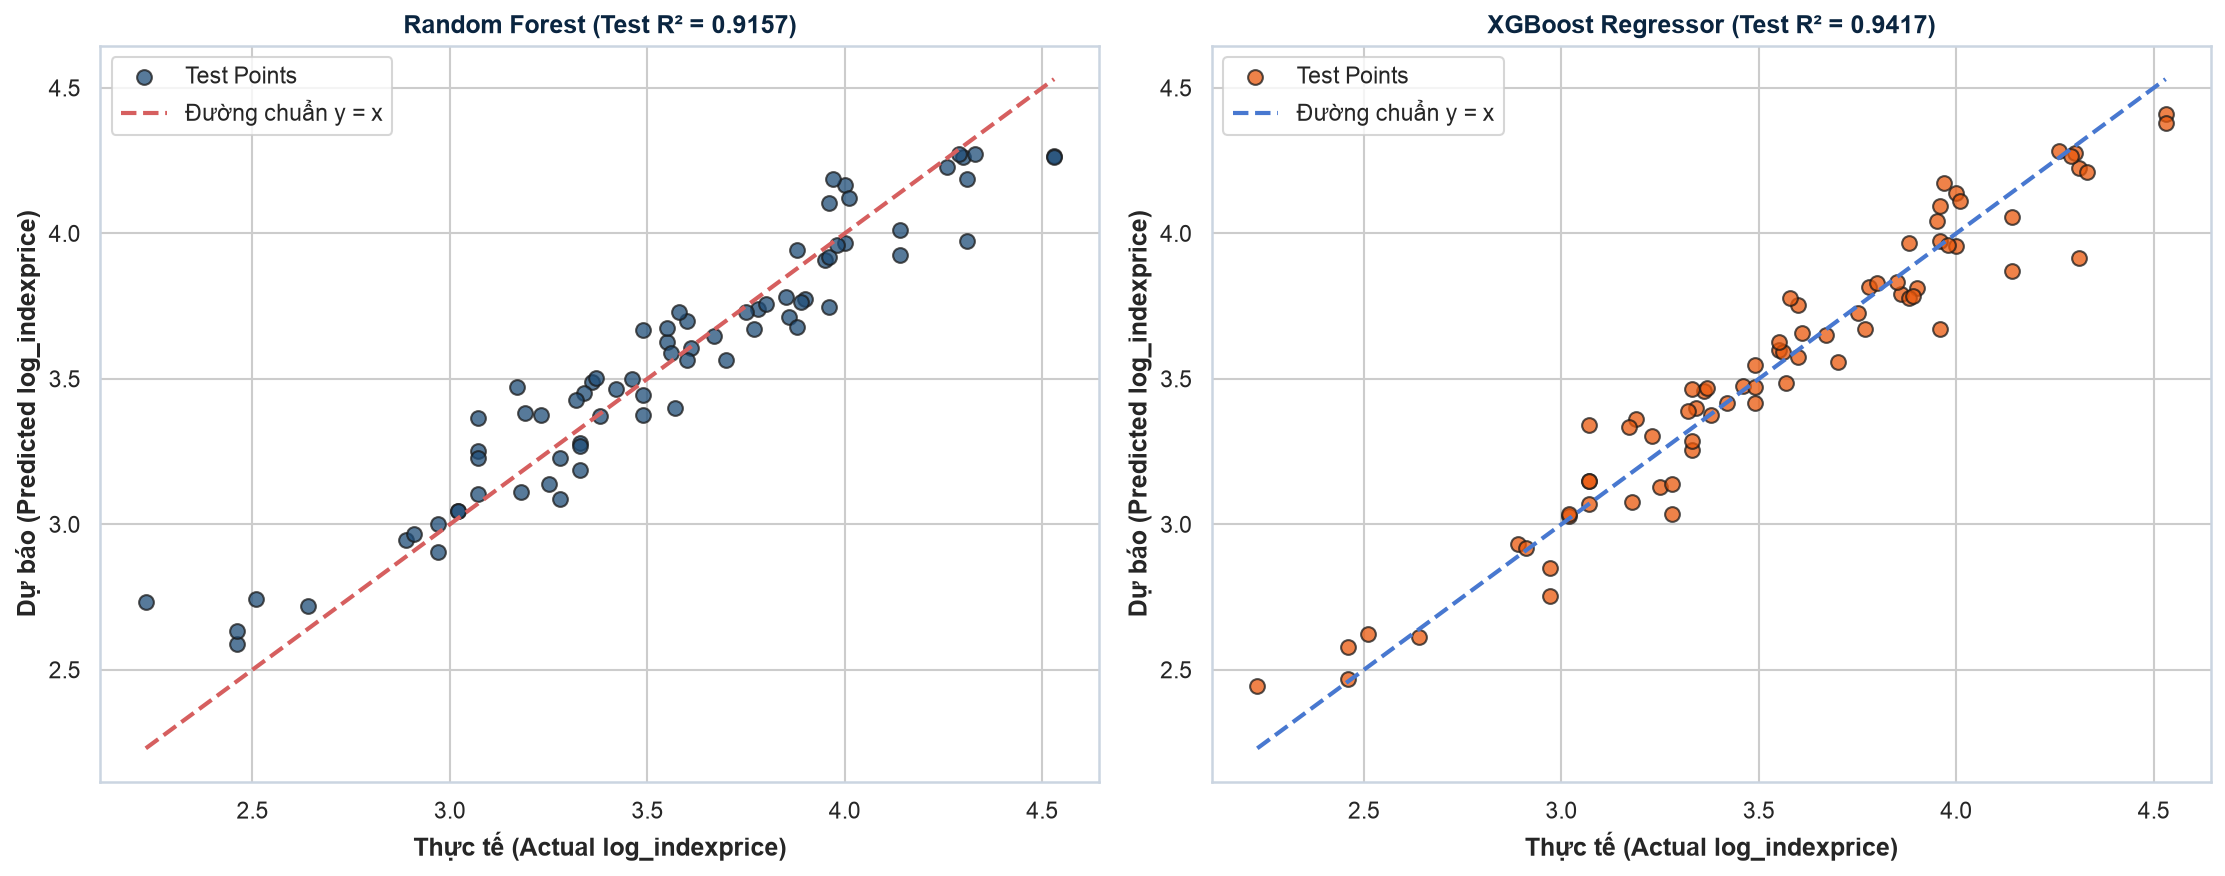

In [9]:
# Trực quan hóa Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Random Forest Scatter
axes[0].scatter(y_test, y_test_pred_rf, color="#1F4D78", alpha=0.75, edgecolors='k', s=50, label="Test Points")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Đường chuẩn y = x")
axes[0].set_title(f"Random Forest (Test R² = {r2_test_rf:.4f})", fontsize=12, fontweight='bold', color="#0A2540")
axes[0].set_xlabel("Thực tế (Actual log_indexprice)", fontweight='bold')
axes[0].set_ylabel("Dự báo (Predicted log_indexprice)", fontweight='bold')
axes[0].legend()

# XGBoost Scatter
axes[1].scatter(y_test, y_test_pred_xgb, color="#EA580C", alpha=0.75, edgecolors='k', s=50, label="Test Points")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'b--', lw=2, label="Đường chuẩn y = x")
axes[1].set_title(f"XGBoost Regressor (Test R² = {r2_test_xgb:.4f})", fontsize=12, fontweight='bold', color="#0A2540")
axes[1].set_xlabel("Thực tế (Actual log_indexprice)", fontweight='bold')
axes[1].set_ylabel("Dự báo (Predicted log_indexprice)", fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Phân Tích Tầm Quan Trọng Của Các Biến (Feature Importances)

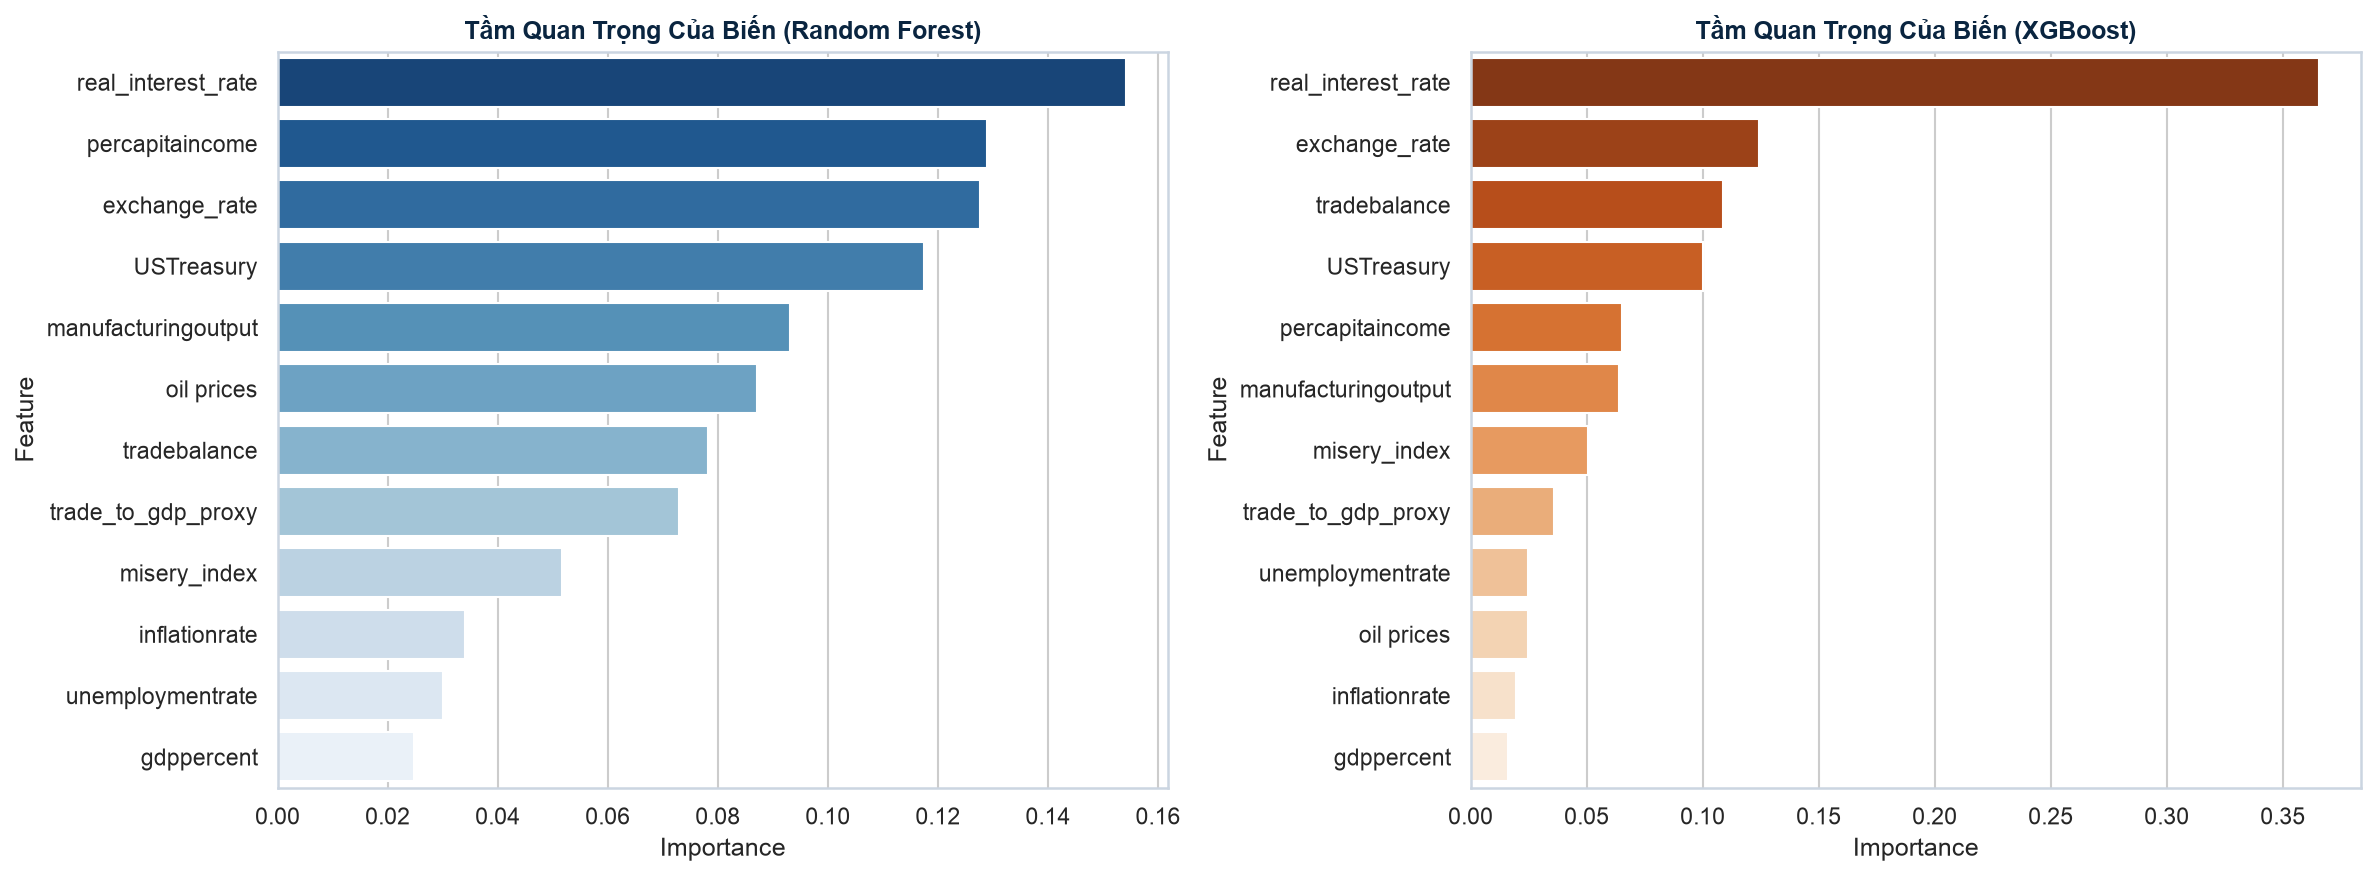

In [10]:
# Tính toán Feature Importance
df_rf_imp = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)
df_xgb_imp = pd.DataFrame({'Feature': feature_cols, 'Importance': xgb_model.feature_importances_}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)
sns.barplot(x='Importance', y='Feature', data=df_rf_imp, ax=axes[0], hue='Feature', palette='Blues_r', legend=False)
axes[0].set_title("Tầm Quan Trọng Của Biến (Random Forest)", fontweight='bold', color="#0A2540")

sns.barplot(x='Importance', y='Feature', data=df_xgb_imp, ax=axes[1], hue='Feature', palette='Oranges_r', legend=False)
axes[1].set_title("Tầm Quan Trọng Của Biến (XGBoost)", fontweight='bold', color="#0A2540")

plt.tight_layout()
plt.show()

## 9. Ứng Dụng Mô Hình Dự Báo Thực Tế Trên Tệp Dữ Liệu Mới (`X_new.xlsx`)

In [11]:
# Đọc tệp dữ liệu kiểm thử mới X_new
df_xnew = pd.read_excel("X_new.xlsx")

# Bổ sung 3 biến phái sinh kinh tế vĩ mô tương ứng
df_xnew_proc = df_xnew.copy()
df_xnew_proc['real_interest_rate'] = df_xnew_proc['USTreasury'] * 100 - df_xnew_proc['inflationrate']
df_xnew_proc['trade_to_gdp_proxy'] = df_xnew_proc['tradebalance'] / (df_xnew_proc['gdppercent'].abs() + 1.0)
df_xnew_proc['misery_index'] = df_xnew_proc['unemploymentrate'] + df_xnew_proc['inflationrate']

# Sắp xếp đúng thứ tự đặc trưng và chuẩn hóa
X_new_features = df_xnew_proc[feature_cols]
X_new_scaled = scaler.transform(X_new_features)

# Thực hiện dự báo với các mô hình
pred_log_lr = lr_model.predict(X_new_scaled)[0]
pred_log_rf = rf_model.predict(X_new_scaled)[0]
pred_log_xgb = xgb_model.predict(X_new_scaled)[0]

df_pred_final = pd.DataFrame([
    {"Mô Hình": "Linear Regression (OLS)", "Dự Báo log_indexprice": round(pred_log_lr, 4), "Giá Trị Quy Đổi index price ($)": round(np.exp(pred_log_lr), 2)},
    {"Mô Hình": "Random Forest Regressor", "Dự Báo log_indexprice": round(pred_log_rf, 4), "Giá Trị Quy Đổi index price ($)": round(np.exp(pred_log_rf), 2)},
    {"Mô Hình": "XGBoost Regressor (Khuyên dùng)", "Dự Báo log_indexprice": round(pred_log_xgb, 4), "Giá Trị Quy Đổi index price ($)": round(np.exp(pred_log_xgb), 2)}
])

print("🎯 KẾT QUẢ DỰ BÁO CUỐI CÙNG TRÊN X_new:")
display(df_pred_final)

🎯 KẾT QUẢ DỰ BÁO CUỐI CÙNG TRÊN X_new:


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


,Mô Hình,Dự Báo log_indexprice,Giá Trị Quy Đổi index price ($)
0,Linear Regression (OLS),3.0807,21.77
1,Random Forest Regressor,2.8730,17.69
2,XGBoost Regressor (Khuyên dùng),2.5270,12.52
